# Circle Detection menggunakan OpenCV Hough Circle Transform

Pipeline:

Original Image
→ Grayscale
→ Gaussian Blur
→ Canny Edge (visualisasi)
→ Hough Circle Transform
→ Deteksi Circle

Metode:

`cv2.HoughCircles()`

Output:

\[
(x_c,y_c,r)
\]

dimana:
- xc = koordinat pusat x
- yc = koordinat pusat y
- r = radius lingkaran


In [656]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


## 1. Load Image

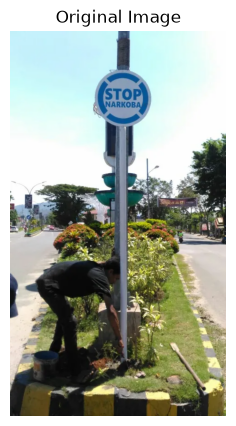

In [657]:
image_path = "stop.png"

img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Image tidak ditemukan")

plt.figure(figsize=(8,5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off");


## 2. Grayscale

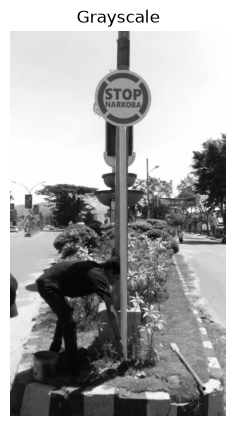

In [658]:
gray = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(8,5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off");


## 3. Gaussian Blur

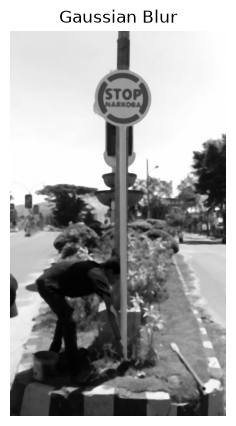

In [659]:
blur = cv2.medianBlur(
    gray,
    5
)

plt.figure(figsize=(8,5))
plt.imshow(blur, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off");


## 4. Canny Edge Detection (Visualisasi)

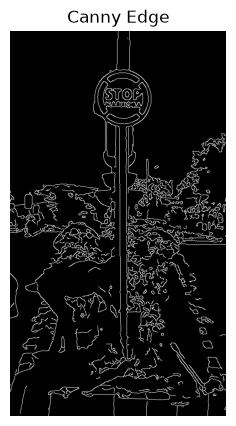

In [665]:
edges = cv2.Canny(
    blur,
    90,
    180
)

plt.figure(figsize=(8,5))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge")
plt.axis("off");


## 5. Hough Circle Transform

Persamaan lingkaran:

\[
(x-x_c)^2+(y-y_c)^2=r^2
\]

OpenCV mencari parameter:

\[
(x_c,y_c,r)
\]

menggunakan voting pada accumulator.


In [713]:
circles = cv2.HoughCircles(
    blur,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=140, #Jarak minimum antar pusat circle yang boleh dideteksi.
    param1=180, #CannyHigh treshold
    param2=55, #Threshold accumulator
    minRadius=55,   #Radius minimum circle yang dicari(r).
    maxRadius=160   #Radius maksimal circle yang dicari(r).
)

if circles is None:
    print("Tidak ada circle ditemukan")
else:
    circles = np.uint16(np.around(circles))
    print("Jumlah circle:", len(circles[0]))


Jumlah circle: 1


## 6. Extract Circle Parameter

In [714]:
if circles is not None:

    for i, circle in enumerate(circles[0]):
        x, y, r = circle
        
        print(
            f"Circle {i+1}:"
        )

        print(
            "Center:",
            (x,y)
        )

        print(
            "Radius:",
            r
        )
        print("----------------")


Circle 1:
Center: (np.uint16(246), np.uint16(146))
Radius: 55
----------------


## 7. Draw Detected Circle

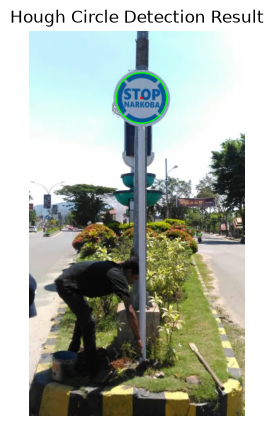

In [715]:
result = img.copy()

if circles is not None:
    for circle in circles[0]:
        x,y,r = circle
        cv2.circle(
            result,
            (x,y),
            r,
            (0,255,0),
            2
        )

        cv2.circle(
            result,
            (x,y),
            3,
            (0,0,255),
            -1
        )

plt.figure(figsize=(8,5))

plt.imshow(
    cv2.cvtColor(
        result,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Hough Circle Detection Result")
plt.axis("off");


## 8. Comparison Original vs Result

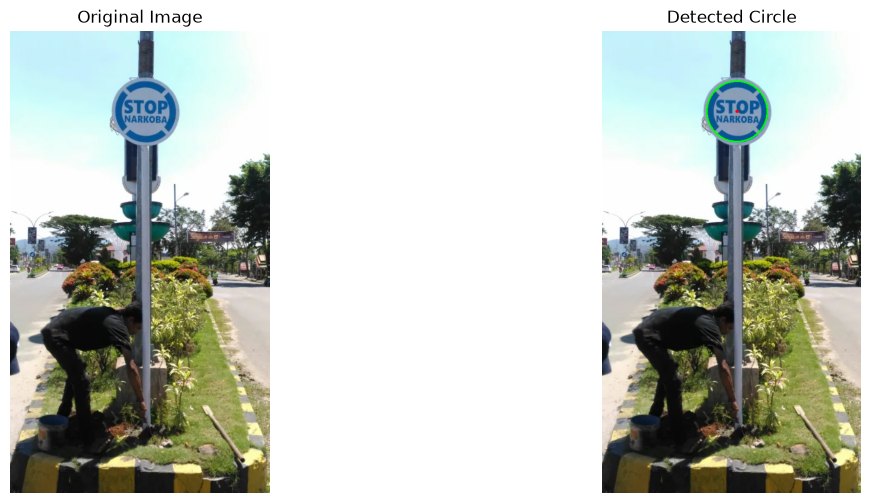

In [716]:
plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Detected Circle")
plt.axis("off")

plt.show()


## Parameter Experiment

Parameter penting:

### dp
Resolusi accumulator.

### minDist
Jarak minimum antar pusat circle.

### param2
Threshold voting:
- kecil → lebih banyak circle terdeteksi
- besar → lebih ketat

### minRadius/maxRadius
Batas ukuran circle.
